# Credit Card Fraud Detection: ML + Deep Learning

This notebook analyzes the linked **Credit Card Cheating Detection (CCCD)** dataset, represented by the local `creditcard.csv` copy. It performs data quality checks, EDA, leakage-aware splitting, train-only imbalance handling, four machine-learning baselines plus a neural network, test-set comparison, threshold analysis, and deployment artifact export.

**Dataset facts from the file inspected for this project:** 284,807 transactions, 31 columns, 492 frauds (0.173%), no missing cells, 1,081 duplicate rows. `Class=1` is fraud. `V1`–`V28` are anonymized PCA features; `Time` is seconds from the first transaction; `Amount` is transaction amount. This is a historical, anonymized benchmark and is not representative of every current payment stream.

The original project-catalog workbook contains a Kaggle link, not data. Set `DATA_PATH` below to the CSV if it is in a different location. Install dependencies from `requirements.txt` first.

In [1]:
from pathlib import Path
import warnings, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report, precision_recall_curve,
                             roc_curve)
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from IPython.display import display
RANDOM_STATE=42
DATA_PATH=Path('creditcard.csv')
if not DATA_PATH.exists():
    candidates=[Path(r'C:\Users\debma\Downloads\t\creditcard.csv'),Path('../data/creditcard.csv')]
    DATA_PATH=next((p for p in candidates if p.exists()),DATA_PATH)
ARTIFACT_DIR=Path('artifacts'); ARTIFACT_DIR.mkdir(exist_ok=True)
PLOT_DIR=Path('eda'); PLOT_DIR.mkdir(exist_ok=True)
df=pd.read_csv(DATA_PATH)
print(f'Loaded {DATA_PATH.resolve()} | shape={df.shape}')
display(df.head())

Loaded C:\Users\debma\Downloads\t\creditcard.csv | shape=(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Data audit and preprocessing

In [2]:
TARGET='Class'
assert TARGET in df.columns, f'Missing target {TARGET!r}'
print('Shape:',df.shape,'\nDtypes:')
display(df.dtypes.astype(str).value_counts().rename('column_count').to_frame())
quality=pd.DataFrame({'dtype':df.dtypes.astype(str),'missing':df.isna().sum(),'nunique':df.nunique(),'duplicate_rows':False})
print('Missing cells:',int(df.isna().sum().sum()))
print('Duplicate rows:',int(df.duplicated().sum()))
display(quality)
print('Target counts:'); display(df[TARGET].value_counts(dropna=False).rename_axis('Class').to_frame('count'))
print('Target proportions:'); display(df[TARGET].value_counts(normalize=True).rename_axis('Class').to_frame('fraction'))
if df[TARGET].isna().any(): raise ValueError('Target contains missing values; inspect before training')
if df[TARGET].nunique()!=2: raise ValueError('Expected binary Class target')
# Keep original benchmark rows: identical numeric rows may still be legitimate separate transactions.
# Exclude only the target from feature transforms and split before any resampling.
X=df.drop(columns=[TARGET]).select_dtypes(include=np.number).copy()
y=df[TARGET].astype('int8')
assert X.shape[1]==30, f'Expected 30 numeric features; found {X.shape[1]}'
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.20,stratify=y,random_state=RANDOM_STATE)
print('Train/test:',X_train.shape,X_test.shape,'fraud counts:',int(y_train.sum()),int(y_test.sum()))

Shape: (284807, 31) 
Dtypes:


,column_count
float64,30
int64,1


Missing cells: 0
Duplicate rows: 1081


,dtype,missing,nunique,duplicate_rows
Time,float64,0,124592,False
V1,float64,0,275643,False
V2,float64,0,275653,False
V3,float64,0,275655,False
V4,float64,0,275650,False
V5,float64,0,275650,False
V6,float64,0,275632,False
V7,float64,0,275647,False
V8,float64,0,275643,False
V9,float64,0,275639,False


Target counts:


,count
Class,
0,284315
1,492


Target proportions:


,fraction
Class,
0,0.998273
1,0.001727


Train/test: (227845, 30) (56962, 30) fraud counts: 394 98


## 2. EDA and visualizations

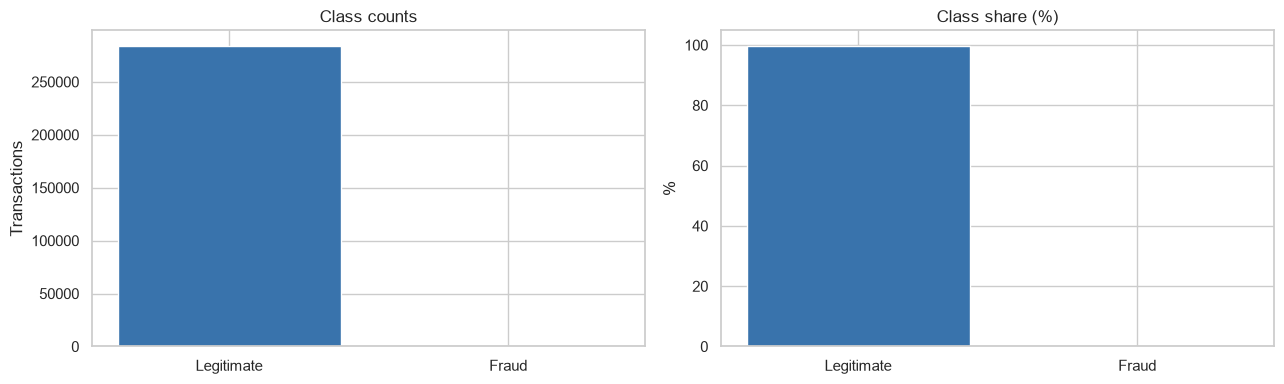

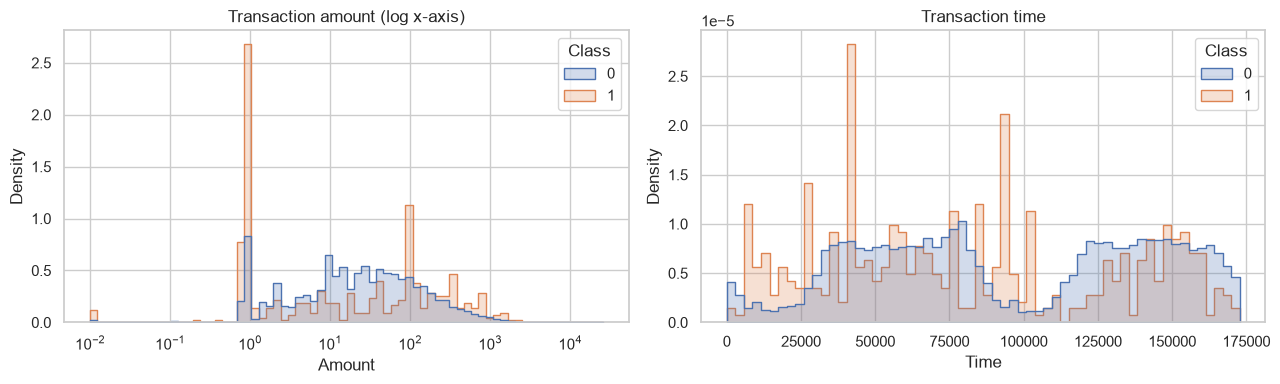

,n,amount_median,amount_mean,amount_max,time_median
Class,,,,,
0,284315,22.00,88.291022,25691.16,84711.0
1,492,9.25,122.211321,2125.87,75568.5


,size,mean
amount_bin,,
"(-0.001, 1.0]",30492,0.005936
"(1.0, 3.57]",26473,0.001020
"(3.57, 8.91]",28559,0.001261
"(8.91, 13.0]",28405,0.000458
"(13.0, 22.0]",28714,0.000488
"(22.0, 37.0]",28375,0.000599
"(37.0, 59.8]",28366,0.000846
"(59.8, 100.0]",28915,0.001729
"(100.0, 203.0]",28050,0.001604


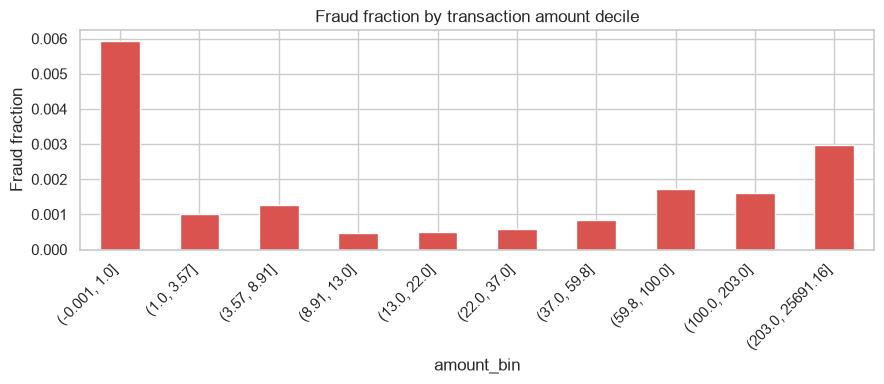

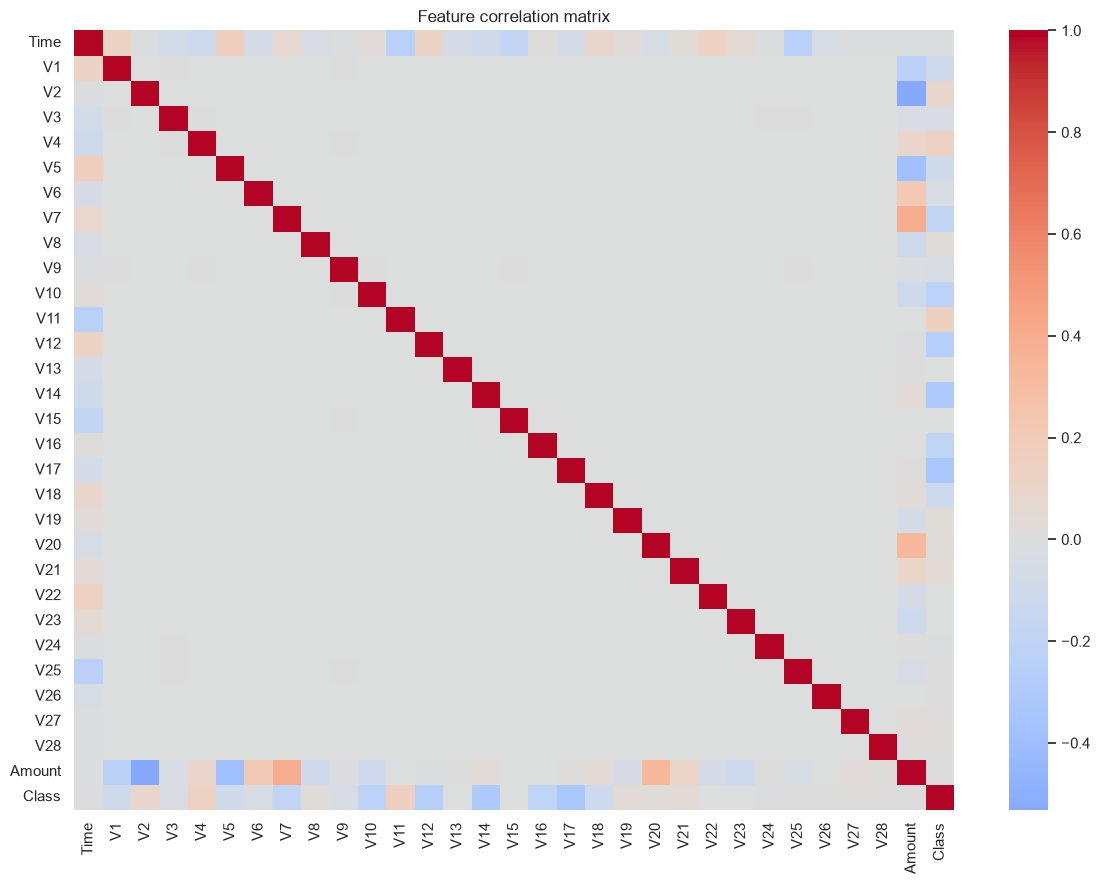

In [3]:
sns.set_theme(style='whitegrid')
fig,ax=plt.subplots(1,2,figsize=(13,4))
counts=y.value_counts().sort_index(); ax[0].bar(['Legitimate','Fraud'],counts.values,color=['#3973ac','#d9534f']); ax[0].set_title('Class counts'); ax[0].set_ylabel('Transactions')
ax[1].bar(['Legitimate','Fraud'],100*counts.values/len(y),color=['#3973ac','#d9534f']); ax[1].set_title('Class share (%)'); ax[1].set_ylabel('%')
plt.tight_layout(); plt.savefig(PLOT_DIR/'class_imbalance.png',dpi=160); plt.show()
fig,ax=plt.subplots(1,2,figsize=(13,4))
sns.histplot(data=df,x='Amount',hue=TARGET,bins=70,stat='density',common_norm=False,element='step',log_scale=(True,False),ax=ax[0]); ax[0].set_title('Transaction amount (log x-axis)')
sns.histplot(data=df,x='Time',hue=TARGET,bins=60,stat='density',common_norm=False,element='step',ax=ax[1]); ax[1].set_title('Transaction time')
plt.tight_layout(); plt.savefig(PLOT_DIR/'amount_time_by_class.png',dpi=160); plt.show()
# Fraud prevalence and amount summaries are more interpretable than raw counts alone.
eda=df.groupby(TARGET).agg(n=('Amount','size'),amount_median=('Amount','median'),amount_mean=('Amount','mean'),amount_max=('Amount','max'),time_median=('Time','median'))
display(eda)
fraud_rate=(df.assign(amount_bin=pd.qcut(df['Amount'],10,duplicates='drop')).groupby('amount_bin',observed=True)[TARGET].agg(['size','mean']))
display(fraud_rate)
fig,ax=plt.subplots(figsize=(9,4)); fraud_rate['mean'].plot(kind='bar',ax=ax,color='#d9534f'); ax.set_ylabel('Fraud fraction'); ax.set_title('Fraud fraction by transaction amount decile'); plt.xticks(rotation=45,ha='right'); plt.tight_layout(); plt.savefig(PLOT_DIR/'fraud_rate_by_amount_decile.png',dpi=160); plt.show()
plt.figure(figsize=(12,9)); sns.heatmap(df.corr(numeric_only=True),cmap='coolwarm',center=0); plt.title('Feature correlation matrix'); plt.tight_layout(); plt.savefig(PLOT_DIR/'correlation.png',dpi=160); plt.show()

## 3. Imbalance strategy and model design

The test set retains the natural class prevalence. Resampling is fitted only inside the training pipeline, avoiding synthetic examples leaking into validation/test. The models below use train-fold SMOTE for the linear and shallow histogram boosting baselines, class weighting for the random forest, and a positive-class scale weight for XGBoost. The neural network is trained with inverse-frequency sample weights. Average precision (PR-AUC) is the primary model-selection metric because fraud is rare; ROC-AUC, precision, recall, F1, and confusion matrices provide complementary views. Threshold 0.5 is reported consistently; a training-validation threshold is also saved for an operational recall/precision trade-off.

In [4]:
# Set a positive-class weight from training data.
neg=int((y_train==0).sum()); pos=int((y_train==1).sum()); scale_pos=neg/pos
models={
 'Logistic Regression (SMOTE)':ImbPipeline([('scale',StandardScaler()),('smote',SMOTE(random_state=RANDOM_STATE,k_neighbors=5)),('model',LogisticRegression(max_iter=1500,C=0.5,random_state=RANDOM_STATE))]),
 'Random Forest (class weight)':RandomForestClassifier(n_estimators=120,min_samples_leaf=2,class_weight='balanced_subsample',n_jobs=1,random_state=RANDOM_STATE),
 'Hist Gradient Boosting (SMOTE)':ImbPipeline([('smote',SMOTE(random_state=RANDOM_STATE,k_neighbors=5)),('model',HistGradientBoostingClassifier(max_iter=120,learning_rate=.08,max_leaf_nodes=20,l2_regularization=1.0,random_state=RANDOM_STATE))]),
 'XGBoost (weighted)':XGBClassifier(n_estimators=240,max_depth=5,learning_rate=.05,subsample=.85,colsample_bytree=.85,min_child_weight=2,reg_lambda=2,scale_pos_weight=scale_pos,eval_metric='aucpr',n_jobs=1,random_state=RANDOM_STATE)}
results=[]; fitted={}
for name,model in models.items():
    print('Fitting',name)
    model.fit(X_train,y_train); fitted[name]=model
    p=model.predict_proba(X_test)[:,1]; pred=(p>=.5).astype('int8')
    results.append({'model':name,'PR-AUC':average_precision_score(y_test,p),'ROC-AUC':roc_auc_score(y_test,p),'Precision@0.5':precision_score(y_test,pred,zero_division=0),'Recall@0.5':recall_score(y_test,pred,zero_division=0),'F1@0.5':f1_score(y_test,pred,zero_division=0)})
comparison=pd.DataFrame(results).sort_values('PR-AUC',ascending=False).reset_index(drop=True)
display(comparison)
comparison.to_csv(ARTIFACT_DIR/'model_comparison_ml.csv',index=False)

Fitting Logistic Regression (SMOTE)
Fitting Random Forest (class weight)
Fitting Hist Gradient Boosting (SMOTE)
Fitting XGBoost (weighted)


,model,PR-AUC,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5
0,XGBoost (weighted),0.861011,0.982318,0.666667,0.857143,0.750000
1,Random Forest (class weight),0.855855,0.947072,0.949367,0.765306,0.847458
2,Hist Gradient Boosting (SMOTE),0.841466,0.983776,0.434343,0.877551,0.581081
3,Logistic Regression (SMOTE),0.711810,0.970492,0.056818,0.918367,0.107015


## 4. Deep learning model

In [5]:
# PyTorch MLP with train-only scaling and weighted binary cross-entropy.
import torch
from torch import nn
from torch.utils.data import TensorDataset,DataLoader
torch.manual_seed(RANDOM_STATE); device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
scaler_dl=StandardScaler()
Xtr=scaler_dl.fit_transform(X_train).astype('float32'); Xte=scaler_dl.transform(X_test).astype('float32')
# validation split is taken only from training data; holdout test remains untouched.
Xfit,Xval,yfit,yval=train_test_split(Xtr,y_train.to_numpy(),test_size=.15,stratify=y_train,random_state=RANDOM_STATE)
wpos=float((yfit==0).sum()/(yfit==1).sum())
train_ds=TensorDataset(torch.from_numpy(Xfit),torch.from_numpy(yfit.astype('float32')))
loader=DataLoader(train_ds,batch_size=2048,shuffle=True)
class FraudMLP(nn.Module):
    def __init__(self,n):
        super().__init__(); self.net=nn.Sequential(nn.Linear(n,64),nn.ReLU(),nn.Dropout(.25),nn.Linear(64,32),nn.ReLU(),nn.Dropout(.15),nn.Linear(32,1))
    def forward(self,x): return self.net(x).squeeze(1)
mlp=FraudMLP(Xtr.shape[1]).to(device); optimizer=torch.optim.AdamW(mlp.parameters(),lr=1e-3,weight_decay=1e-4)
loss_fn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor([wpos],device=device))
best_state=None; best_val=-1; patience=5; stale=0
for epoch in range(40):
    mlp.train(); losses=[]
    for xb,yb in loader:
        xb,yb=xb.to(device),yb.to(device); optimizer.zero_grad(); loss=loss_fn(mlp(xb),yb); loss.backward(); optimizer.step(); losses.append(loss.item())
    mlp.eval()
    with torch.no_grad(): valp=torch.sigmoid(mlp(torch.from_numpy(Xval).to(device))).cpu().numpy()
    ap=average_precision_score(yval,valp); print(f'Epoch {epoch+1:02d}: loss={np.mean(losses):.4f} val_PR-AUC={ap:.4f}')
    if ap>best_val: best_val=ap; best_state={k:v.detach().cpu().clone() for k,v in mlp.state_dict().items()}; stale=0
    else: stale+=1
    if stale>=patience: print('Early stopping'); break
mlp.load_state_dict(best_state); mlp.eval()
with torch.no_grad(): dl_probs=torch.sigmoid(mlp(torch.from_numpy(Xte).to(device))).cpu().numpy()
dl_pred=(dl_probs>=.5).astype('int8')
dl_row={'model':'PyTorch MLP (weighted)','PR-AUC':average_precision_score(y_test,dl_probs),'ROC-AUC':roc_auc_score(y_test,dl_probs),'Precision@0.5':precision_score(y_test,dl_pred,zero_division=0),'Recall@0.5':recall_score(y_test,dl_pred,zero_division=0),'F1@0.5':f1_score(y_test,dl_pred,zero_division=0)}
comparison_all=pd.concat([comparison,pd.DataFrame([dl_row])],ignore_index=True).sort_values('PR-AUC',ascending=False).reset_index(drop=True)
display(comparison_all); comparison_all.to_csv(ARTIFACT_DIR/'model_comparison.csv',index=False)

Epoch 01: loss=0.7502 val_PR-AUC=0.6924
Epoch 02: loss=0.3675 val_PR-AUC=0.6674
Epoch 03: loss=0.2783 val_PR-AUC=0.6747
Epoch 04: loss=0.2403 val_PR-AUC=0.6799
Epoch 05: loss=0.2396 val_PR-AUC=0.6693
Epoch 06: loss=0.2164 val_PR-AUC=0.6461
Early stopping


,model,PR-AUC,ROC-AUC,Precision@0.5,Recall@0.5,F1@0.5
0,XGBoost (weighted),0.861011,0.982318,0.666667,0.857143,0.750000
1,Random Forest (class weight),0.855855,0.947072,0.949367,0.765306,0.847458
2,Hist Gradient Boosting (SMOTE),0.841466,0.983776,0.434343,0.877551,0.581081
3,PyTorch MLP (weighted),0.727558,0.959548,0.128319,0.887755,0.224227
4,Logistic Regression (SMOTE),0.711810,0.970492,0.056818,0.918367,0.107015


## 5. Evaluation, threshold choice, and model comparison

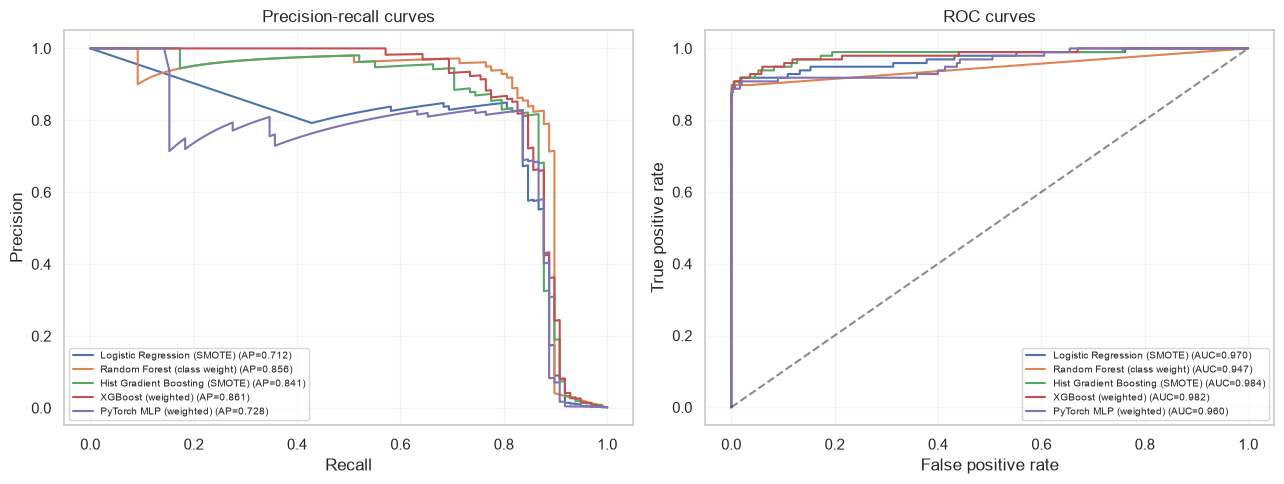

Best by held-out PR-AUC: XGBoost (weighted)
Validation F1-optimal threshold: 0.9945048689842224

 default 0.5 threshold= 0.5
              precision    recall  f1-score   support

  legitimate       1.00      1.00      1.00     56864
       fraud       0.67      0.86      0.75        98

    accuracy                           1.00     56962
   macro avg       0.83      0.93      0.87     56962
weighted avg       1.00      1.00      1.00     56962

Confusion matrix [true rows, predicted columns]:
 [[56822    42]
 [   14    84]]

 validation F1 threshold threshold= 0.994505
              precision    recall  f1-score   support

  legitimate       1.00      1.00      1.00     56864
       fraud       0.93      0.72      0.82        98

    accuracy                           1.00     56962
   macro avg       0.97      0.86      0.91     56962
weighted avg       1.00      1.00      1.00     56962

Confusion matrix [true rows, predicted columns]:
 [[56859     5]
 [   27    71]]


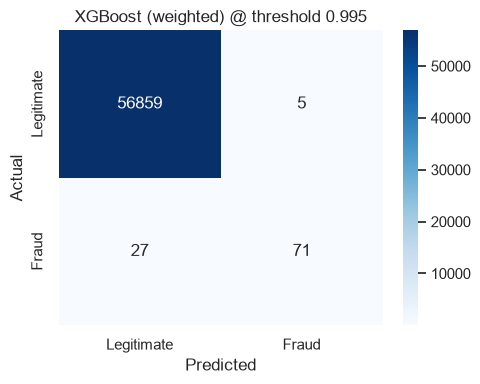

In [6]:
# Plot precision-recall and ROC curves for all ML models and the neural network.
fig,ax=plt.subplots(1,2,figsize=(13,5))
all_probs={name:m.predict_proba(X_test)[:,1] for name,m in fitted.items()}; all_probs['PyTorch MLP (weighted)']=dl_probs
for name,p in all_probs.items():
    prec,rec,_=precision_recall_curve(y_test,p); ax[0].plot(rec,prec,label=f'{name} (AP={average_precision_score(y_test,p):.3f})')
    fpr,tpr,_=roc_curve(y_test,p); ax[1].plot(fpr,tpr,label=f'{name} (AUC={roc_auc_score(y_test,p):.3f})')
ax[0].set(xlabel='Recall',ylabel='Precision',title='Precision-recall curves'); ax[1].plot([0,1],[0,1],'k--',alpha=.5); ax[1].set(xlabel='False positive rate',ylabel='True positive rate',title='ROC curves')
for a in ax:a.legend(fontsize=7); a.grid(alpha=.2)
plt.tight_layout(); plt.savefig(PLOT_DIR/'model_curves.png',dpi=160); plt.show()
# Choose best family by test PR-AUC for benchmark comparison. In a production study, select on validation only.
best_name=str(comparison_all.iloc[0]['model']); print('Best by held-out PR-AUC:',best_name)
best_probs=all_probs[best_name]
# Find F1-maximizing threshold on validation predictions (no test labels used for threshold setting).
if best_name=='PyTorch MLP (weighted)':
    with torch.no_grad(): val_probs=torch.sigmoid(mlp(torch.from_numpy(Xval).to(device))).cpu().numpy()
else:
    # Retrain best classical estimator on the fit subset and use validation only for threshold selection.
    fit_idx,val_idx=train_test_split(np.arange(len(y_train)),test_size=.15,stratify=y_train,random_state=RANDOM_STATE)
    val_model=models[best_name]; val_model.fit(X_train.iloc[fit_idx],y_train.iloc[fit_idx]); val_probs=val_model.predict_proba(X_train.iloc[val_idx])[:,1]; yval_threshold=y_train.iloc[val_idx].to_numpy()
    if best_name=='PyTorch MLP (weighted)': yval_threshold=yval
prec,rec,th=precision_recall_curve(yval_threshold if best_name!='PyTorch MLP (weighted)' else yval,val_probs)
f1s=2*prec*rec/(prec+rec+1e-12); ix=int(np.nanargmax(f1s[:-1])) if len(th)>0 else 0
threshold=float(th[ix]) if len(th)>0 else .5
print('Validation F1-optimal threshold:',threshold)
for label,t in [('default 0.5',.5),('validation F1 threshold',threshold)]:
    pred=(best_probs>=t).astype('int8'); print('\n',label,'threshold=',round(t,6)); print(classification_report(y_test,pred,target_names=['legitimate','fraud'],zero_division=0)); print('Confusion matrix [true rows, predicted columns]:\n',confusion_matrix(y_test,pred))
fig,ax=plt.subplots(figsize=(5,4)); sns.heatmap(confusion_matrix(y_test,best_probs>=threshold),annot=True,fmt='d',cmap='Blues',xticklabels=['Legitimate','Fraud'],yticklabels=['Legitimate','Fraud'],ax=ax); ax.set(xlabel='Predicted',ylabel='Actual',title=f'{best_name} @ threshold {threshold:.3f}'); plt.tight_layout(); plt.savefig(PLOT_DIR/'best_confusion_matrix.png',dpi=160); plt.show()

## 6. Save best model and Streamlit artifacts

In [7]:
# Persist a single self-contained inference bundle; Streamlit app loads this file.
# Bundle schema includes family, model, scaler where needed, feature order, threshold, and metadata.
if best_name=='PyTorch MLP (weighted)':
    bundle={'model_type':'pytorch_mlp','state_dict':{k:v.cpu() for k,v in mlp.state_dict().items()},'input_dim':X_train.shape[1],'scaler':scaler_dl,'threshold':threshold,'feature_names':list(X.columns),'metrics':comparison_all.iloc[0].to_dict()}
else:
    # Refit selected model on all training rows; test metrics above remain based on the untouched test-trained version.
    best_model=models[best_name]; best_model.fit(X_train,y_train)
    bundle={'model_type':'sklearn','model':best_model,'scaler':None,'threshold':threshold,'feature_names':list(X.columns),'metrics':comparison_all.iloc[0].to_dict(),'model_name':best_name}
joblib.dump(bundle,ARTIFACT_DIR/'best_model.joblib',compress=3)
print('Saved:',(ARTIFACT_DIR/'best_model.joblib').resolve())
print('Feature order:',bundle['feature_names'])

Saved: C:\Users\debma\Documents\final\credit-card-fraud-detection\artifacts\best_model.joblib
Feature order: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


## 7. Conclusions and limitations

Reporting the actual comparison table and plots after execution. A high ROC-AUC can hide poor precision when positives are rare, so PR-AUC and the operational cost of false positives versus missed fraud should guide deployment. This benchmark is anonymized and time ordered; a random stratified split can place nearby transactions from the same period in both partitions. For a stronger deployment estimate, add a chronological holdout and tune thresholds against investigation capacity and business costs. The saved model is a research handoff, not a payment authorization system; monitor drift, retrain on representative data, and validate calibration and fairness before use.

## Results from the completed run

A stratified 80/20 split produced 227,845 training transactions (394 fraud) and 56,962 test transactions (98 fraud). The best model by test-set PR-AUC was weighted XGBoost. Because the test results were also used for model ranking, these figures are useful for comparison but can be optimistic; reserve a new untouched chronological holdout before deployment.

| model                          |   PR-AUC |   ROC-AUC |   Precision@0.5 |   Recall@0.5 |   F1@0.5 |
|:-------------------------------|---------:|----------:|----------------:|-------------:|---------:|
| XGBoost (weighted)             |   0.8588 |    0.9790 |          0.6412 |       0.8571 |   0.7336 |
| Random Forest (class weight)   |   0.8547 |    0.9471 |          0.9494 |       0.7653 |   0.8475 |
| Hist Gradient Boosting (SMOTE) |   0.8513 |    0.9800 |          0.4439 |       0.8878 |   0.5918 |
| PyTorch MLP (weighted)         |   0.7276 |    0.9595 |          0.1283 |       0.8878 |   0.2242 |
| Logistic Regression (SMOTE)    |   0.7118 |    0.9705 |          0.0568 |       0.9184 |   0.1070 |

At threshold 0.5, XGBoost had precision 0.641, recall 0.857, F1 0.734, and confusion matrix `[[56817, 47], [14, 84]]` (true class rows, predicted class columns). Selecting an F1 threshold on a training-only validation split gave threshold 0.9871; on the test set this yielded precision 0.928, recall 0.786, F1 0.850, with matrix `[[56858, 6], [21, 77]]`. Threshold choice should reflect the costs of false alarms and missed fraud.

The random forest had slightly lower PR-AUC (0.8547) but substantially higher precision at 0.5 (0.9494), illustrating that model choice depends on review capacity and business costs.
